**1. Entorno y archivos protegidos**

Se usa el entorno de la sesión IA07, que hereda tesis-fcl y solo añade Optuna. Este notebook presenta resultados ya generados por el script reproducible; no repite la búsqueda ni reevalúa la prueba. Los datos, la partición y los notebooks 07 y 08 se tratan como solo lectura.

In [1]:
from pathlib import Path
import json, sys, unittest
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/feature_engineering.py').is_file())
sys.path.insert(0, str(ROOT))
import src.optimizacion_hiperparametros as oh
OUT = oh.OUT
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.float_format', '{:,.3f}'.format)
leer = lambda n, **k: pd.read_csv(OUT / n, **k)
MONEDA = {'D lares': 'Dólares', 'Soles': 'Soles'}
nombre = lambda t: t.assign(moneda=t.moneda.replace(MONEDA))
display(pd.DataFrame([json.loads((OUT / 'entorno.json').read_text())]).T.rename(columns={0: 'versión'}))
integridad = oh.estado_archivos_previos()
assert integridad['cambios_git'] == []
print('Archivos protegidos sin cambios frente a git:', ', '.join(integridad['rutas']))

,versión
python,3.12.15
optuna,4.9.0
scikit-learn,1.9.1
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
git_head,8239c27312cb8d800222d06cf8e644a1a269b0db


Archivos protegidos sin cambios frente a git: data, reports/sprint_06, notebooks/07_baseline_variantes.ipynb, notebooks/08_mejoras_baseline.ipynb


El entorno usa las mismas versiones de scikit-learn, NumPy y pandas que tesis-fcl. Los datos, los resultados del Sprint 06 y los notebooks 07 y 08 no tienen cambios frente a git.

**2. Diagnóstico de los experimentos previos**

El notebook 07 fijó alpha = 1 sin búsqueda. El notebook 08 evaluó seis valores de alpha con recorte p1/p99 y validación temporal, y congeló una especificación por cohorte. Se muestran sus resultados de prueba, tomados de sus archivos originales.

In [2]:
s06 = oh.ROOT / 'reports/sprint_06'
b07 = pd.read_csv(s06 / 'resultados_experimentos.csv')
b07 = b07[b07.escenario.eq('principal') & b07.particion.eq('prueba')]
display(nombre(b07)[['moneda', 'experimento', 'alpha', 'n', 'MAE', 'RMSE', 'R2']].reset_index(drop=True))
s08 = pd.read_csv(s06 / 'mejoras/seleccion_congelada_cv.csv')
a08 = pd.read_csv(s06 / 'mejoras/alphas_optimos.csv')
m08 = pd.read_csv(s06 / 'mejoras/metricas_mejoras.csv')
m08 = m08[m08.particion.eq('prueba') & m08.seleccionado_cv.astype(bool)]
display(nombre(m08)[['moneda', 'grupo_ajuste', 'especificacion', 'experimento', 'alpha', 'n', 'MAE', 'RMSE', 'R2']].reset_index(drop=True))
display(a08.alpha.value_counts().sort_index().rename('óptimos por valor de alpha').to_frame())

,moneda,experimento,alpha,n,MAE,RMSE,R2
0,Dólares,E0_financiero,1.000,92,"228,054.366","804,755.456",-2.030
1,Dólares,E1_macroeconomico,1.000,92,"317,991.403","1,343,050.292",-7.440
2,Dólares,E2_bursatil,1.000,92,"237,509.574","759,493.125",-1.699
3,Soles,E0_financiero,1.000,599,"379,977.437","1,424,709.068",-1.490
4,Soles,E1_macroeconomico,1.000,599,"442,301.867","1,445,744.746",-1.564
5,Soles,E2_bursatil,1.000,599,"426,780.010","1,438,296.559",-1.538


,moneda,grupo_ajuste,especificacion,experimento,alpha,n,MAE,RMSE,R2
0,Dólares,no_bancario,niveles_t_externos_t_1,E1_macroeconomico,"1,000.000",92,"147,873.251","323,976.808",0.509
1,Dólares,todas,niveles_t_externos_t_1,E1_macroeconomico,"1,000.000",92,"147,873.251","323,976.808",0.509
2,Soles,bancario,niveles_t_externos_t_1,E1_macroeconomico,10.000,82,"4,299,569.796","5,683,160.613",-5.485
3,Soles,no_bancario,sin_niveles_t_externos_t_1,E2_bursatil,"1,000.000",517,"124,751.254","280,239.196",0.461
4,Soles,todas,niveles_t_externos_t,E1_macroeconomico,10.000,599,"476,969.630","1,640,420.194",-2.301


,óptimos por valor de alpha
alpha,
10.000,7
100.000,11
"1,000.000",22
"10,000.000",5


Todos los R² de prueba del 07 son negativos. La rejilla del 08 es gruesa: 22 de sus 45 óptimos son alpha = 1.000 y 5 tocan el límite de 10.000, lo que justifica un espacio continuo y más amplio. La prueba 2022 a 2025 ya fue inspeccionada en esos notebooks, de modo que aquí no puede ser confirmatoria.

**3. Datos, partición y ventanas temporales**

Se conservan los 3.560 casos y la partición original. Las ventanas son las del notebook 08 y solo contienen años objetivo hasta 2021. La cohorte dólares no bancaria coincide fila a fila con la cohorte dólares completa y no se repite.

In [3]:
m, lag, fin, ratios = oh.cargar_muestra()
conteo = pd.DataFrame([dict(moneda=mo, grupo=gr, entrenamiento=int(oh.subconjunto(m, mo, gr).particion.eq('entrenamiento').sum()), prueba=int(oh.subconjunto(m, mo, gr).particion.eq('prueba').sum())) for mo, gr in oh.COHORTES])
display(nombre(conteo))
pl = leer('pliegues.csv')
assert pl.anio_validacion_max.max() == 2021
display(nombre(pl))

,moneda,grupo,entrenamiento,prueba
0,Dólares,todas,353,92
1,Soles,todas,2516,599
2,Soles,no_bancario,2344,517
3,Soles,bancario,172,82


,moneda,grupo,fold,anio_entrenamiento_min,anio_entrenamiento_max,anio_validacion_min,anio_validacion_max,n_entrenamiento,n_validacion
0,Dólares,todas,1,2006,2013,2014,2015,154,54
1,Dólares,todas,2,2006,2015,2016,2017,208,47
2,Dólares,todas,3,2006,2017,2018,2019,255,51
3,Dólares,todas,4,2006,2019,2020,2021,306,47
4,Soles,todas,1,2006,2013,2014,2015,1155,357
5,Soles,todas,2,2006,2015,2016,2017,1512,352
6,Soles,todas,3,2006,2017,2018,2019,1864,331
7,Soles,todas,4,2006,2019,2020,2021,2195,321
8,Soles,no_bancario,1,2006,2013,2014,2015,1138,319
9,Soles,no_bancario,2,2006,2015,2016,2017,1457,314


Las cuatro cohortes mantienen sus filas originales. Hay cuatro ventanas en tres cohortes y dos en banca, que solo tiene datos desde 2013. Ninguna ventana alcanza los años de prueba.

**4. Protocolo, espacio de búsqueda y presupuesto equivalente**

El protocolo se escribió antes de ejecutar. Random Search y TPE comparten objetivo, ventanas, semillas y número de trials; solo cambia el muestreador de Optuna. Las características quedan fijas en cada estudio y no forman parte de la búsqueda.

In [4]:
protocolo = json.loads((OUT / 'protocolo.json').read_text(encoding='utf-8'))
assert protocolo == json.loads(json.dumps(oh.protocolo(), ensure_ascii=False))
display(pd.DataFrame({'Hiperparámetro': ['alpha', 'escalador', 'recorte de ratios'],
                      'Espacio': [f'log-uniforme entre {oh.ALPHA_MIN:g} y {oh.ALPHA_MAX:g}', ', '.join(oh.ESCALADORES), ', '.join(oh.RECORTES)],
                      'Antecedente': ['Rejilla del 08: 0,1 a 10.000', 'Sensibilidad del 07', 'p01_p99 del 08; se añaden sin recorte y p05_p95']}))
display(pd.DataFrame({'Elemento': ['Estudios (cohorte y características)', 'Métodos', 'Semillas por método', 'Trials por corrida', 'Trials totales', 'Pruning'],
                      'Valor': [len(oh.COHORTES) * len(oh.CARACTERISTICAS), 2, len(oh.SEMILLAS), oh.PRESUPUESTO, len(oh.COHORTES) * len(oh.CARACTERISTICAS) * 2 * len(oh.SEMILLAS) * oh.PRESUPUESTO, 'Ninguno (NopPruner)']}))

,Hiperparámetro,Espacio,Antecedente
0,alpha,log-uniforme entre 0.01 y 1e+07,"Rejilla del 08: 0,1 a 10.000"
1,escalador,"standard, robust",Sensibilidad del 07
2,recorte de ratios,"sin_recorte, p01_p99, p05_p95",p01_p99 del 08; se añaden sin recorte y p05_p95


,Elemento,Valor
0,Estudios (cohorte y características),16
1,Métodos,2
2,Semillas por método,20
3,Trials por corrida,60
4,Trials totales,38400
5,Pruning,Ninguno (NopPruner)


Son 16 estudios, 20 semillas y 60 trials por corrida para cada método: 19.200 trials por método. Los 10 primeros trials de TPE son aleatorios y, con la misma semilla, coinciden con los de Random Search, por lo que ambos métodos solo pueden diferir a partir del trial 11.

**5. Reproducción del baseline Ridge**

Antes de comparar se comprueba que el código reutilizable reproduce el baseline del 07 sin alterarlo. El ajuste usa entrenamiento y las cifras se contrastan con el archivo original.

In [5]:
filas = []
for mo in ('D lares', 'Soles'):
    t = oh.subconjunto(m, mo, 'todas')
    tr, te = oh.solo_entrenamiento(t), t[t.particion.eq('prueba')]
    for ca, ex in (('E0_07', 'E0_financiero'), ('E1_07', 'E1_macroeconomico'), ('E2_07', 'E2_bursatil')):
        _, cols = oh.caracteristicas(ca, (mo, 'todas'), m, lag, fin)
        p = oh.crear_pipeline(cols, ratios, 1.).fit(tr[cols], tr.objetivo_fcl_t1).predict(te[cols])
        r = float(np.sqrt(np.mean((p - te.objetivo_fcl_t1) ** 2)))
        o = b07[b07.moneda.eq(mo) & b07.experimento.eq(ex)].RMSE.iloc[0]
        np.testing.assert_allclose(r, o, rtol=1e-9)
        filas.append(dict(moneda=mo, experimento=ex, RMSE_recalculado=r, RMSE_notebook_07=o))
display(nombre(pd.DataFrame(filas)))

,moneda,experimento,RMSE_recalculado,RMSE_notebook_07
0,Dólares,E0_financiero,"804,755.456","804,755.456"
1,Dólares,E1_macroeconomico,"1,343,050.292","1,343,050.292"
2,Dólares,E2_bursatil,"759,493.125","759,493.125"
3,Soles,E0_financiero,"1,424,709.068","1,424,709.068"
4,Soles,E1_macroeconomico,"1,445,744.746","1,445,744.746"
5,Soles,E2_bursatil,"1,438,296.559","1,438,296.559"


Los seis RMSE coinciden con el notebook 07. Las pruebas automatizadas amplían esta comprobación a las predicciones completas del 07, a 216 puntuaciones de validación del 08 (las otras 54 son de la cohorte de dólares repetida) y a sus predicciones congeladas.

**6. Registro de trials**

Cada trial guarda su configuración, el MSE por ventana, el estado y la duración. La misma búsqueda se repitió completa en una carpeta temporal para comprobar que es determinista.

In [6]:
trials = leer('trials.csv')
n = trials.groupby([*oh.ID_ESTUDIO, 'metodo', 'semilla']).size()
assert n.eq(oh.PRESUPUESTO).all() and trials.estado.eq('COMPLETE').all()
display(trials.groupby('metodo').agg(trials=('trial', 'size'), semillas=('semilla', 'nunique'), duracion_mediana_s=('duracion_s', 'median'), duracion_total_s=('duracion_s', 'sum')))
display(nombre(trials.head(4)))
print(json.loads((OUT / 'verificacion_determinismo.json').read_text()))

,trials,semillas,duracion_mediana_s,duracion_total_s
metodo,,,,
random_search,19200,20,0.013,447.046
tpe,19200,20,0.017,508.955


,moneda,grupo,caracteristicas,metodo,semilla,trial,alpha,escalador,recorte,mse_cv,rmse_cv,mse_fold_1,mse_fold_2,mse_fold_3,mse_fold_4,estado,duracion_s
0,Dólares,todas,E0_07,random_search,20261103,0,0.167,standard,sin_recorte,"372,124,701,667.499","610,020.247","383,477,174,245.635","374,293,131,543.690","618,888,717,658.442","111,839,783,222.230",COMPLETE,0.101
1,Dólares,todas,E0_07,random_search,20261103,1,0.032,standard,sin_recorte,"380,281,973,569.731","616,670.069","396,087,411,641.604","377,405,530,066.072","635,648,384,681.003","111,986,567,890.245",COMPLETE,0.006
2,Dólares,todas,E0_07,random_search,20261103,2,"2,593.731",robust,p05_p95,"132,079,649,709.095","363,427.640","161,030,882,928.194","52,983,648,125.861","226,738,368,970.079","87,565,698,812.245",COMPLETE,0.075
3,Dólares,todas,E0_07,random_search,20261103,3,"1,167,800.198",robust,sin_recorte,"83,955,968,383.709","289,751.563","129,630,035,459.838","26,669,094,134.885","66,159,217,085.868","113,365,526,854.245",COMPLETE,0.070


{'trials_identicos': True, 'referencia_densa_identica': True, 'seleccion_identica': True, 'sha256_seleccion': '9ee2e553a717bd57dc8e9976650a6fece4cdbac22ab32ea062f302ed34f4f220', 'filas_trials': 38400}


Todos los trials terminan completos y cada corrida consume exactamente 60. Un trial tarda unos 13 ms en Random Search y 17 ms en TPE, de modo que el costo no limita la búsqueda. Repetir la búsqueda produjo los mismos trials y la misma selección.

**7. Convergencia de Random Search y TPE**

La brecha es la distancia, en porcentaje de RMSE de validación, al mejor valor conocido de cada estudio. Ese valor incluye una referencia densa de 181 alphas por combinación, que solo mide la distancia y nunca selecciona. No interviene la prueba.

,n_trials,estudios,brecha_mediana_random_search,brecha_mediana_tpe,peor_mediana_random_search,peor_mediana_tpe,estudios_tpe_menor,estudios_rs_menor,estudios_p_menor_005,estudios_p_holm_menor_005
0,6,16,1.294,1.294,7.597,7.597,0,0,0,0
1,10,16,0.900,0.900,7.070,7.070,0,0,0,0
2,20,16,0.537,0.173,3.640,1.999,14,2,5,1
3,30,16,0.396,0.087,1.905,1.213,16,0,5,4
4,60,16,0.142,0.064,0.571,1.208,13,3,8,4


,moneda,grupo,caracteristicas,brecha_mediana_random_search,brecha_mediana_tpe,brecha_maxima_random_search,brecha_maxima_tpe,p_mann_whitney,p_holm
0,Dólares,todas,E0_07,0.519,1.208,2.275,1.236,0.882,1.000
1,Dólares,todas,E1_07,0.300,0.261,1.629,0.287,0.004,0.047
2,Dólares,todas,E2_07,0.571,0.730,2.118,0.758,0.473,1.000
3,Dólares,todas,seleccion_08,0.478,0.037,2.959,7.046,0.001,0.014
4,Soles,bancario,E0_07,0.129,0.001,0.616,0.124,0.000,0.000
5,Soles,bancario,E1_07,0.185,0.247,0.351,0.265,0.776,1.000
6,Soles,bancario,E2_07,0.136,0.128,0.230,0.168,0.285,1.000
7,Soles,bancario,seleccion_08,0.069,0.033,0.261,0.883,0.010,0.112
8,Soles,no_bancario,E0_07,0.147,0.063,0.611,3.494,0.068,0.543
9,Soles,no_bancario,E1_07,0.148,0.064,0.604,3.516,0.068,0.543


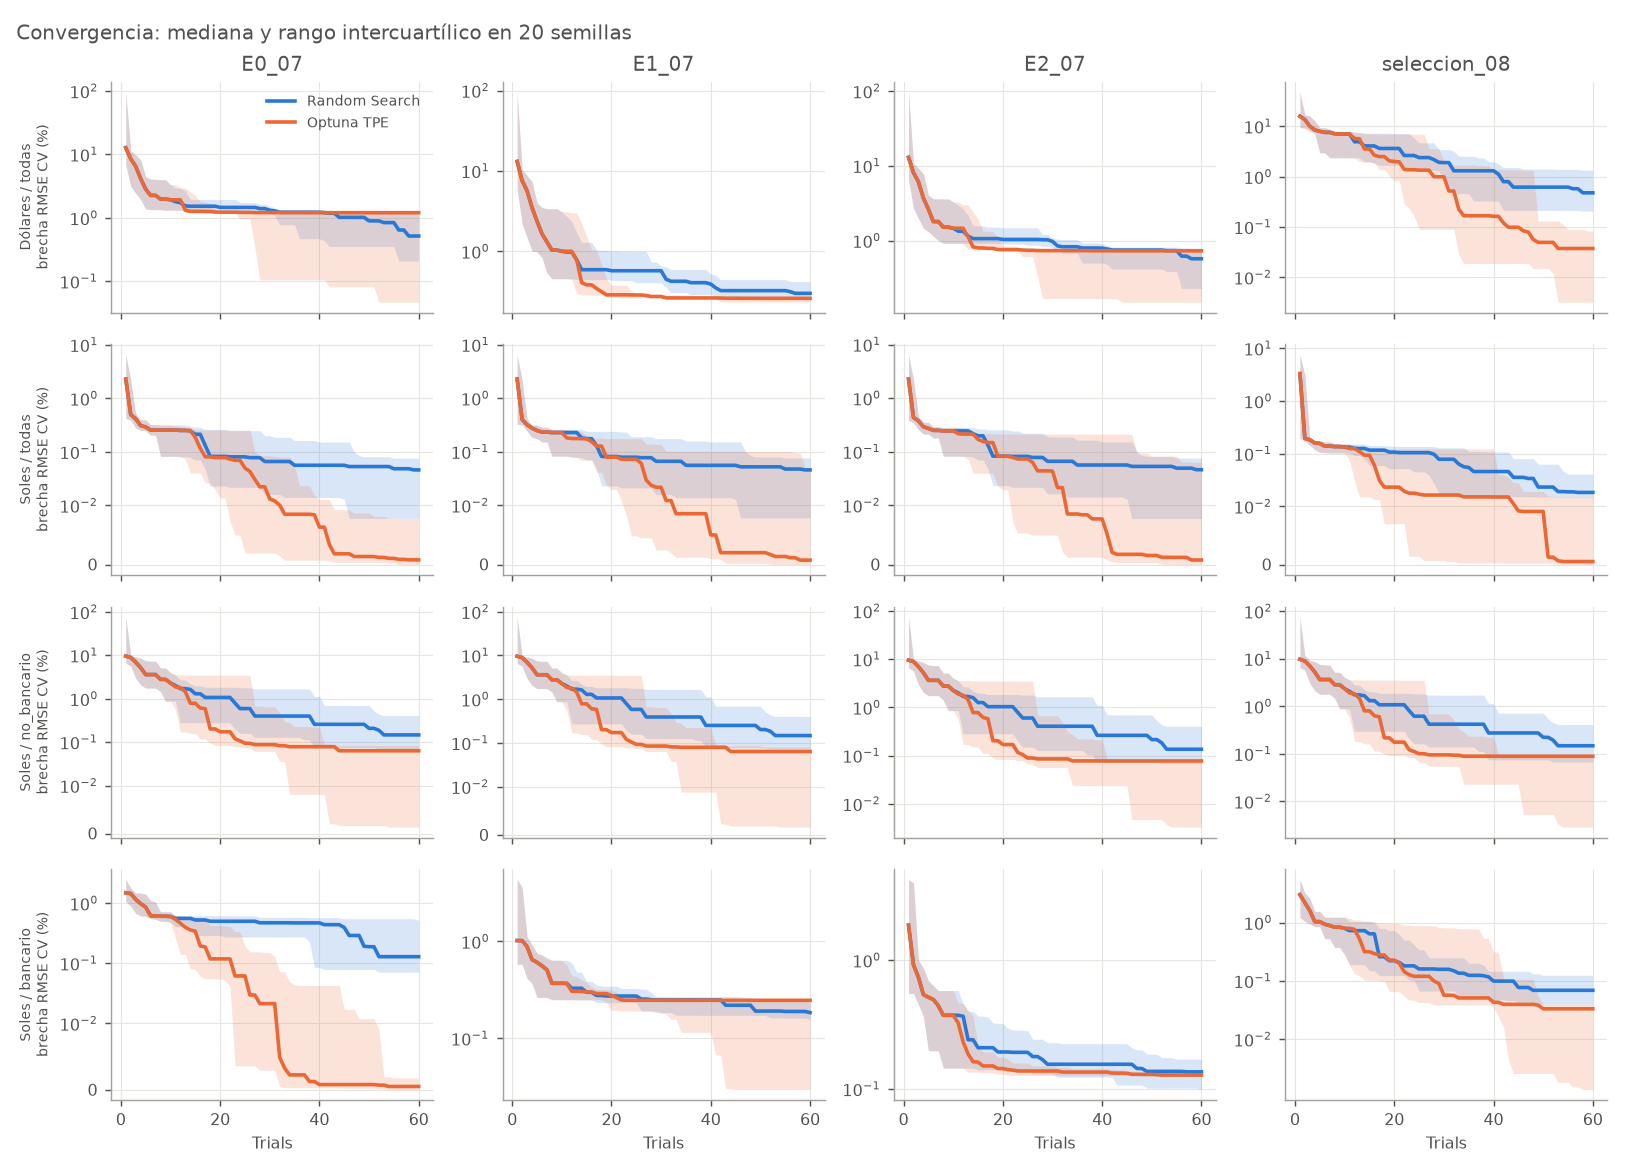

In [7]:
display(leer('comparacion_metodos_agregada.csv'))
comp = leer('comparacion_metodos.csv')
display(nombre(comp[comp.n_trials.eq(60)])[['moneda', 'grupo', 'caracteristicas', 'brecha_mediana_random_search', 'brecha_mediana_tpe', 'brecha_maxima_random_search', 'brecha_maxima_tpe', 'p_mann_whitney', 'p_holm']].reset_index(drop=True))
display(Image(str(OUT / 'graficos/convergencia.png')))

Con 60 trials, la brecha mediana es 0,14 % en Random Search y 0,06 % en TPE. TPE tiene menor mediana en 13 de 16 estudios, y la diferencia se sostiene tras el ajuste de Holm en 4. Son diferencias muy pequeñas, de 0,69 puntos porcentuales como máximo. TPE converge antes en mediana, pero tiene peor caso: alguna corrida queda a 7,05 % del mejor valor, frente a 2,96 % en Random Search, y su peor caso es mayor en 6 estudios. El ajuste de Holm se añadió al análisis después de ver los valores sin ajustar.

**8. Respuesta a los hiperparámetros**

Se muestra el RMSE de validación frente a alpha en la especificación del 08, con la semilla principal. La tabla resume cuánto se aleja cada nivel categórico del mejor resultado del estudio. Es una lectura descriptiva, no una medida formal de importancia.

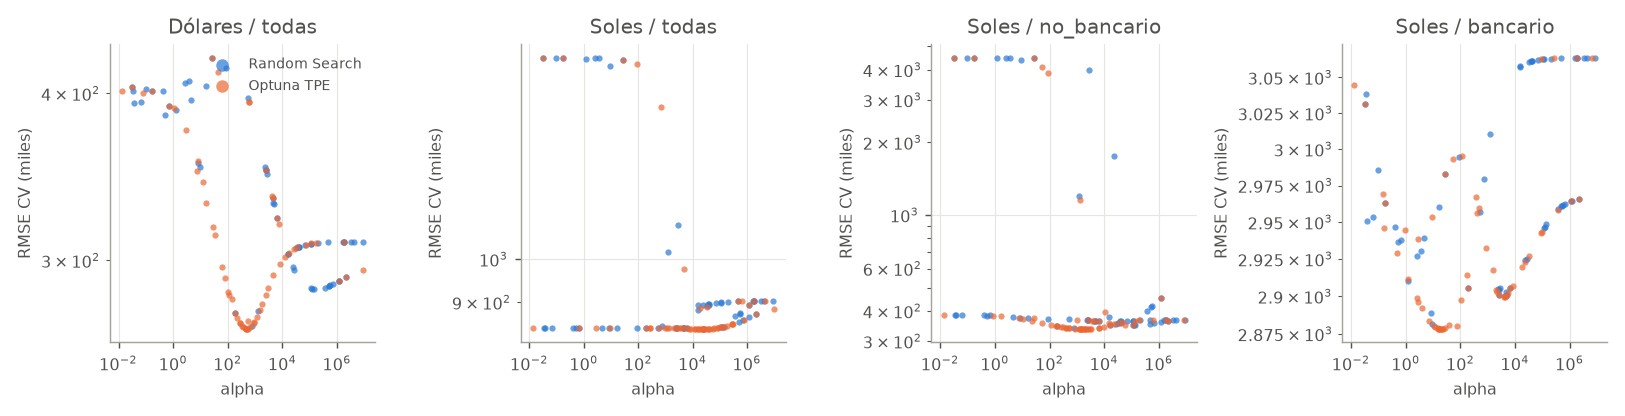

brecha mediana (%)  brecha máxima (%)
hiperparametro nivel                                             
escalador      robust                    0.671              7.034
               standard                  0.000              0.255
recorte        p01_p99                   0.080              0.491
               p05_p95                   0.000              0.066
               sin_recorte               1.798              7.870

In [8]:
display(Image(str(OUT / 'graficos/respuesta_alpha.png')))
efecto = leer('efecto_categoricos.csv')
display(efecto.groupby(['hiperparametro', 'nivel']).brecha_con_mejor_pct.agg(['median', 'max']).rename(columns={'median': 'brecha mediana (%)', 'max': 'brecha máxima (%)'}))

Alpha domina la respuesta. No recortar ratios aleja una mediana de 1,80 % del mejor resultado, mientras que p05_p95 y p01_p99 quedan casi empatados. El escalador robusto solo gana en la cohorte de soles completa, con alphas mucho mayores que no son comparables con los de StandardScaler.

**9. Configuraciones ganadoras**

Las configuraciones se eligieron por validación con la semilla principal y se congelaron con hash antes de calcular métricas de prueba. El ganador de cohorte es el de menor error de validación entre sus cuatro estudios.

In [9]:
sel = leer('seleccion_congelada.csv')
reg = oh.verificar_congelacion(OUT)
print('SHA-256 de la selección:', reg['sha256'], '| congelada:', reg['congelada_utc'])
orden = ['ridge_alpha1', 'rejilla_08', 'random_search', 'tpe']
g = sel[sel.ganador_cohorte].assign(o=lambda d: d.procedimiento.map({p: i for i, p in enumerate(orden)})).sort_values(['moneda', 'grupo', 'o'])
display(nombre(g)[['moneda', 'grupo', 'procedimiento', 'caracteristicas', 'alpha', 'escalador', 'recorte', 'rmse_cv']].reset_index(drop=True))
cv = sel.pivot_table(index=oh.ID_ESTUDIO, columns='procedimiento', values='rmse_cv')
cambios = pd.DataFrame({'rejilla_frente_a_alpha1': cv.rejilla_08 / cv.ridge_alpha1 - 1, 'random_search_frente_a_rejilla': cv.random_search / cv.rejilla_08 - 1, 'tpe_frente_a_rejilla': cv.tpe / cv.rejilla_08 - 1, 'tpe_frente_a_random_search': cv.tpe / cv.random_search - 1}) * 100
display(cambios.describe().loc[['min', '50%', 'max']])

SHA-256 de la selección: 9ee2e553a717bd57dc8e9976650a6fece4cdbac22ab32ea062f302ed34f4f220 | congelada: 2026-11-03T22:43:31.536244+00:00


,moneda,grupo,procedimiento,caracteristicas,alpha,escalador,recorte,rmse_cv
0,Dólares,todas,ridge_alpha1,seleccion_08,1.000,standard,sin_recorte,"391,118.270"
1,Dólares,todas,rejilla_08,seleccion_08,"1,000.000",standard,p01_p99,"270,451.556"
2,Dólares,todas,random_search,seleccion_08,758.696,standard,p05_p95,"268,105.755"
3,Dólares,todas,tpe,seleccion_08,474.100,standard,p01_p99,"266,653.251"
4,Soles,bancario,ridge_alpha1,seleccion_08,1.000,standard,sin_recorte,"2,914,211.962"
5,Soles,bancario,rejilla_08,seleccion_08,10.000,standard,p01_p99,"2,886,677.156"
6,Soles,bancario,random_search,seleccion_08,9.394,standard,sin_recorte,"2,881,307.971"
7,Soles,bancario,tpe,seleccion_08,18.986,standard,sin_recorte,"2,878,338.218"
8,Soles,no_bancario,ridge_alpha1,E2_07,1.000,standard,sin_recorte,"4,415,835.915"
9,Soles,no_bancario,rejilla_08,E2_07,"1,000.000",standard,p01_p99,"338,385.035"


,rejilla_frente_a_alpha1,random_search_frente_a_rejilla,tpe_frente_a_rejilla,tpe_frente_a_random_search
min,-92.479,-0.867,-1.404,-0.563
50%,-51.116,-0.200,-0.297,-0.086
max,-0.945,0.123,-0.096,0.158


En validación, casi toda la ganancia viene de pasar de alpha = 1 a un alpha regularizado: la rejilla reduce el RMSE una mediana de 51 %. Sobre la rejilla, Random Search baja una mediana de 0,20 % y TPE 0,30 %, y Random Search queda por encima de la rejilla en 5 estudios pese a usar 60 trials frente a 6. Ningún alpha ganador está cerca de los límites del espacio.

**10. Limitaciones del pruning y del early stopping en Ridge**

No se implementa ninguno de los dos. Ridge con solver SVD tiene solución cerrada: no hay iteraciones ni curva de aprendizaje que interrumpir, de modo que el early stopping no tiene objeto, y cambiar a un solver iterativo solo para crear pasos sería artificial. El pruning de Optuna solo podría actuar entre ventanas temporales, que no son réplicas intercambiables. Con los trials ya registrados se mide qué arriesgaría, sin ejecutar ningún pruner.

In [10]:
diag = leer('diagnostico_pruning.csv')
display(nombre(diag[diag.ventanas_observadas.eq(1)])[['moneda', 'grupo', 'caracteristicas', 'ventanas_totales', 'spearman_parcial_final', 'semillas_donde_mediana_descartaria_ganador_pct']].reset_index(drop=True))
display(diag.groupby('ventanas_observadas').spearman_parcial_final.describe()[['min', '50%', 'max']])

,moneda,grupo,caracteristicas,ventanas_totales,spearman_parcial_final,semillas_donde_mediana_descartaria_ganador_pct
0,Dólares,todas,E0_07,4,0.900,0
1,Dólares,todas,E1_07,4,0.903,0
2,Dólares,todas,E2_07,4,0.906,0
3,Dólares,todas,seleccion_08,4,0.802,0
4,Soles,bancario,E0_07,2,-0.356,20
5,Soles,bancario,E1_07,2,0.375,0
6,Soles,bancario,E2_07,2,0.310,5
7,Soles,bancario,seleccion_08,2,-0.191,5
8,Soles,no_bancario,E0_07,4,-0.064,50
9,Soles,no_bancario,E1_07,4,-0.060,40


,min,50%,max
ventanas_observadas,,,
1,-0.356,0.214,0.906
2,0.342,0.928,0.956
3,0.470,0.900,0.980


Tras la primera ventana, la correlación entre el error parcial y el final tiene una mediana de 0,21 y llega a ser negativa. Una regla de mediana habría descartado al ganador en alguna semilla en 10 de 16 estudios, y en todas las semillas en tres estudios de soles completa. Además, un trial tarda milisegundos, de modo que el pruning ahorraría muy poco y rompería la igualdad de presupuesto entre métodos.

**11. Evaluación única en prueba**

Las configuraciones congeladas se reajustan con todo el entrenamiento de su cohorte y se evalúan una vez en 2022 a 2025, sin devolver información a la búsqueda. Las referencias son la media de entrenamiento y la persistencia, definidas como en el 08.

,moneda,grupo,procedimiento,caracteristicas,alpha,n,MAE,RMSE,RMSE_anual_medio,R2,R2_OOS_media,R2_OOS_persistencia
0,Dólares,todas,media_entrenamiento,ninguna,NaN,92,"225,128.716","464,780.612","461,247.653",-0.011,0.000,-0.814
1,Dólares,todas,persistencia,ninguna,NaN,92,"150,235.043","345,072.950","331,595.821",0.443,0.449,0.000
2,Dólares,todas,random_search,seleccion_08,758.696,92,"144,246.725","316,367.472","297,868.542",0.532,0.537,0.159
3,Dólares,todas,rejilla_08,seleccion_08,"1,000.000",92,"147,873.251","323,976.808","308,943.202",0.509,0.514,0.119
4,Dólares,todas,ridge_alpha1,seleccion_08,1.000,92,"397,650.473","2,069,678.793","1,305,405.648",-19.044,-18.829,-34.974
5,Dólares,todas,tpe,seleccion_08,474.100,92,"138,871.662","310,895.289","286,133.585",0.548,0.553,0.188
6,Soles,todas,media_entrenamiento,ninguna,NaN,599,"310,160.199","907,106.075","824,422.719",-0.009,0.000,0.433
7,Soles,todas,persistencia,ninguna,NaN,599,"346,717.324","1,204,777.095","1,155,279.412",-0.781,-0.764,0.000
8,Soles,todas,random_search,seleccion_08,"27,453.573",599,"397,474.626","1,527,178.794","1,476,998.471",-1.861,-1.834,-0.607
9,Soles,todas,rejilla_08,seleccion_08,10.000,599,"476,969.630","1,640,420.194","1,580,803.156",-2.301,-2.270,-0.854


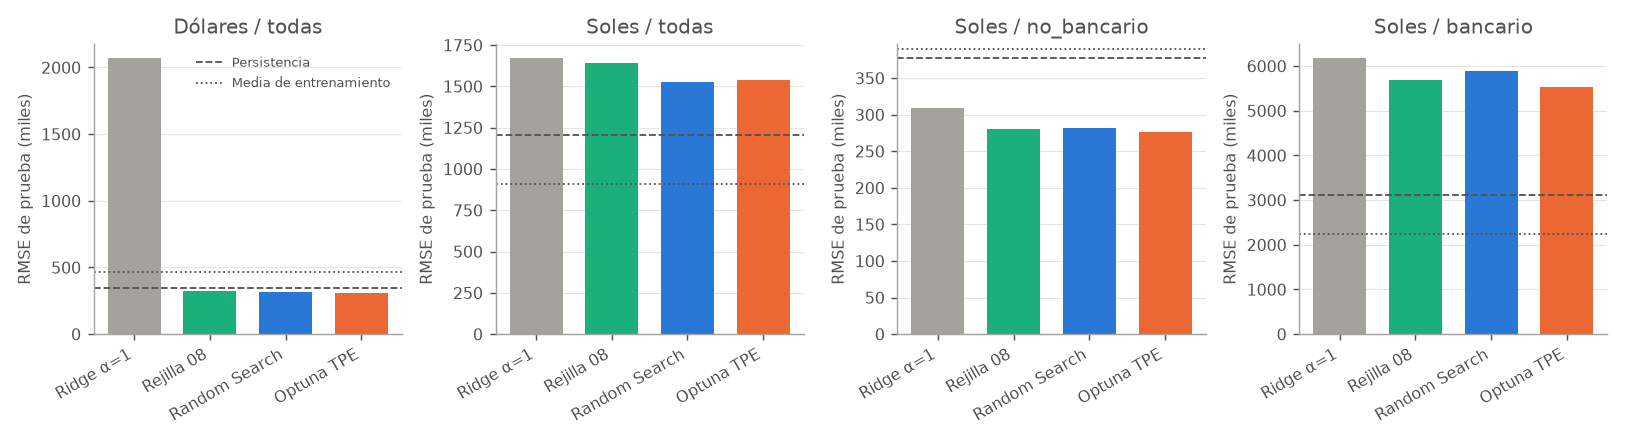

procedimiento                        ridge_alpha1    rejilla_08  random_search           tpe  tpe_frente_a_random_search_pct
moneda  grupo       caracteristicas                                                                                         
D lares todas       E0_07             804,755.456   357,572.672    347,575.070   343,252.676                          -1.244
                    E1_07           1,343,050.292   357,803.002    348,442.185   349,431.538                           0.284
                    E2_07             759,493.125   358,610.286    349,342.646   349,982.905                           0.183
                    seleccion_08    2,069,678.793   323,976.808    316,367.472   310,895.289                          -1.730
Soles   bancario    E0_07           4,088,298.406 3,659,709.528  3,985,154.719 3,569,072.026                         -10.441
                    E1_07           5,356,941.802 3,100,273.302  2,845,890.494 3,043,420.642                           6.941
                    E2_07           3,609,888.925 2,863,444.251  2,717,729.088 2,717,729.088                           0.000
                    seleccion_08    6,174,949.616 5,683,160.613  5,890,436.223 5,528,767.854                          -6.140
        no_bancario E0_07             304,040.557   278,194.711    279,479.767   275,364.347                          -1.473
                    E1_07             308,385.698   278,684.173    280,335.124   275,411.015                          -1.757
                    E2_07             307,201.456   278,744.740    280,231.210   275,555.252                          -1.669
                    seleccion_08      308,642.081   280,239.196    282,198.215   276,267.793                          -2.102
        todas       E0_07           1,424,709.068 1,377,309.817  1,251,032.560 1,307,245.430                           4.493
                    E1_07           1,445,744.746 1,392,963.868  1,251,037.695 1,370,566.518                           9.554
                    E2_07           1,438,296.559 1,387,363.495  1,251,009.831 1,362,015.085                           8.873
                    seleccion_08    1,670,553.978 1,640,420.194  1,527,178.794 1,539,277.801                           0.792

Estudios con menor RMSE de prueba: TPE 8 | Random Search 7 | empate 1


anio_objetivo                              2022          2023          2024          2025
moneda  grupo       procedimiento                                                        
Dólares todas       random_search   428,825.300   197,933.032   381,131.548   183,584.287
                    rejilla_08      426,101.041   208,526.298   388,448.002   212,697.467
                    ridge_alpha1    456,813.428   308,923.665   369,739.278 4,086,146.221
                    tpe             432,393.949   187,769.176   381,985.446   142,385.767
Soles   bancario    random_search 4,043,245.172 8,796,898.586 4,401,687.060 4,877,411.615
                    rejilla_08    4,039,389.764 8,250,521.374 4,427,674.373 4,850,007.217
                    ridge_alpha1  4,517,752.114 8,990,867.774 4,660,261.061 5,273,167.530
                    tpe           3,906,476.206 8,218,432.762 4,242,419.251 4,458,658.832
        no_bancario random_search   246,544.407   200,174.564   383,751.746   268,321.054
                    rejilla_08      243,491.028   200,557.272   379,000.898   269,439.811
                    ridge_alpha1    280,895.660   228,008.271   412,482.151   285,227.059
                    tpe             240,543.944   202,038.930   370,909.590   265,627.378
        todas       random_search 1,576,407.961 1,900,172.952 1,537,652.613   893,760.355
                    rejilla_08    1,736,969.796 2,063,599.878 1,593,274.497   929,368.453
                    ridge_alpha1  1,782,068.639 2,104,731.873 1,613,602.256   928,631.573
                    tpe           1,592,240.123 1,918,604.553 1,543,288.539   898,742.555

In [11]:
met = leer('metricas_prueba.csv')
assert (json.loads((OUT / 'evaluacion_prueba.json').read_text())['sha256_seleccion'] == reg['sha256'])
cols = ['moneda', 'grupo', 'procedimiento', 'caracteristicas', 'alpha', 'n', 'MAE', 'RMSE', 'RMSE_anual_medio', 'R2', 'R2_OOS_media', 'R2_OOS_persistencia']
g = met[met.ganador_cohorte.fillna(False).astype(bool) | met.caracteristicas.eq('ninguna')]
display(nombre(g)[cols].reset_index(drop=True))
display(Image(str(OUT / 'graficos/prueba_por_cohorte.png')))
rm = met[met.caracteristicas.ne('ninguna')].pivot_table(index=oh.ID_ESTUDIO, columns='procedimiento', values='RMSE')[orden]
rm['tpe_frente_a_random_search_pct'] = 100 * (rm.tpe / rm.random_search - 1)
display(rm)
print('Estudios con menor RMSE de prueba: TPE', int((rm.tpe < rm.random_search).sum()), '| Random Search', int((rm.tpe > rm.random_search).sum()), '| empate', int((rm.tpe == rm.random_search).sum()))
anual = leer('metricas_prueba_por_anio.csv')
display(nombre(anual[anual.caracteristicas.eq('seleccion_08')]).pivot_table(index=['moneda', 'grupo', 'procedimiento'], columns='anio_objetivo', values='RMSE'))

Sobre la misma especificación, tanto Random Search como TPE mejoran mucho frente a alpha = 1 en dólares. Entre ambos no hay un ganador: TPE tiene menor RMSE de prueba en 8 estudios, Random Search en 7 y empatan en 1. Las diferencias de prueba llegan a 10 %, muy por encima de las de validación, que no pasan de 0,56 %; configuraciones casi equivalentes en validación generalizan distinto, y eso no se puede atribuir al muestreador con una sola semilla evaluada.

Dólares y soles no bancarios superan a persistencia y a la media de entrenamiento. Soles completa no supera a ninguna de las dos, y la banca pesa mucho en su error. En banca, todos los procedimientos ajustados son peores que la media de entrenamiento, con R² de prueba negativo, y los ganadores de validación también son peores que persistencia. Además, el ganador por validación en banca es peor en prueba que otras especificaciones; esa selección no se cambia.

**12. Comprobaciones automatizadas**

Se ejecutan las pruebas de esta sesión: partición, reproducción de los notebooks 07 y 08, ausencia de fuga, determinismo, presupuestos, congelación y métricas.

In [12]:
suite = unittest.defaultTestLoader.loadTestsFromName('tests.test_optimizacion_hiperparametros')
r = unittest.TextTestRunner(verbosity=0, stream=sys.stdout).run(suite)
assert r.wasSuccessful()
print('Pruebas ejecutadas:', r.testsRun, '| omitidas:', len(r.skipped))

----------------------------------------------------------------------
Ran 26 tests in 10.158s

OK


Pruebas ejecutadas: 26 | omitidas: 0


Las pruebas de esta sesión aprueban. El resultado de la suite completa del repositorio y los fallos históricos están en el informe técnico para la auditoría.

**13. Conclusiones y límites**

Optimizar alpha importa mucho más que el método de búsqueda. En un espacio pequeño y barato de evaluar, TPE converge algo antes en validación, pero con peor caso, y no muestra ventaja en prueba. Frente a la rejilla del 08 en validación, TPE mejora en los 16 estudios y Random Search en 11, siempre por menos de 1,5 %.

Los resultados son exploratorios. La prueba ya se había inspeccionado en los notebooks 07 y 08, la especificación seleccion_08 proviene de las mismas ventanas y solo se evaluó en prueba la semilla principal. El objetivo sigue siendo el FCL preliminar, no un FCFF validado. Este trabajo queda pendiente de la auditoría independiente y de la revisión final.

El detalle está en el [informe de resultados](../../reports/ia07/informe_resultados.md) y en el [informe técnico para la auditoría](../../reports/ia07/informe_auditoria_kimi.md).